# Real NeMo AutoModel LoRA

This tutorial performs real GPU training, saves and reloads the adapter, and compares an identical held-out test set. The default small model is Qwen2.5 0.5B Instruct, not Omni-FinAI. Prefer the bounded Taipei-1 job for reproducible runtime and resources; the original 70B profile needs multiple GPUs. No training results are pre-filled.

In [ ]:
import os, pathlib, subprocess, sys
REPO_URL = "https://github.com/virginiakm1988/omni-finai-nvidia.git"
GIT_REF = "v0.1.0"  # Published, fixed source release for this tutorial.
checkout = pathlib.Path("/content/omni-finai-nvidia")
if not checkout.exists():
    subprocess.run(["git", "clone", REPO_URL, str(checkout)], check=True)
subprocess.run(["git", "-C", str(checkout), "checkout", GIT_REF], check=True)
os.chdir(checkout)
GPU_ENV = "small-tested"  # Use "distributed" in a fresh multi-GPU environment for original70B.
if GPU_ENV not in {"small-tested", "distributed"}:
    raise ValueError("Unknown GPU environment")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"requirements-gpu-{GPU_ENV}.txt", "-e", ".[notebook]"], check=True)
print("Source revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())

# Backport the documented upstream import fix before importing AutoModel.
subprocess.run([sys.executable, "scripts/patch_automodel_0_7_triton.py"], check=True)


## Architecture

The diagram is authored for this tutorial. Each arrow maps to executable package code. Fixture and live results remain explicitly separated.

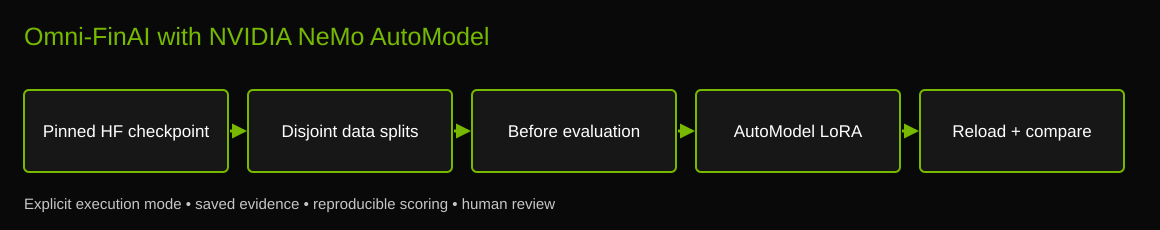

In [2]:
from IPython.display import SVG, display
display(SVG(filename="assets/overview.svg"))

In [3]:
import ipywidgets as widgets
from IPython.display import display
profile = widgets.Dropdown(options=[("Different small teaching base", "small"), ("Original 70B", "original")], value="small", description="Profile")
gpus = widgets.Dropdown(options=[1, 2, 4, 8], value=1, description="GPU count")
run_training = widgets.Checkbox(value=False, description="Run real GPU training")
display(profile, gpus, run_training)


Dropdown(description='Profile', options=(('Different small teaching base', 'small'), ('Original 70B', 'origina…

Dropdown(description='GPU count', options=(1, 2, 4, 8), value=1)

Checkbox(value=False, description='Run real GPU training')

In [4]:
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    print("Optional HF_TOKEN was not loaded. The configured public checkpoints can be downloaded without it; gated replacements require access.")
subprocess.run([sys.executable, "-m", "project_demo", "prepare", "--output-dir", "runs/train-data"], check=True)


Optional HF_TOKEN was not loaded. The configured public checkpoints can be downloaded without it; gated replacements require access.


CompletedProcess(args=['[workspace]\\work\\agent-finance-venv\\Scripts\\python.exe', '-m', 'project_demo', 'prepare', '--output-dir', 'runs/train-data'], returncode=0)

## Train and evaluate

The next cell requires a CUDA runtime. It records the initial model, updates LoRA weights using AutoModel, exports the adapter, checks nonzero LoRA-B tensors, reloads with PEFT, and evaluates the same held-out test rows. A lack of improvement is a valid measured result.

In [5]:
if not run_training.value:
    print("Training not executed. Select a GPU runtime and enable the checkbox to run it. Saved real validation evidence is shown below when available.")
else:
    if profile.value == "original" and GPU_ENV != "distributed":
        raise ValueError("Original70B requires GPU_ENV=distributed and a fresh multi-GPU runtime; see the playbook.")
    subprocess.run([sys.executable, "-m", "project_demo", "train", "--mode", "live", "--profile", profile.value, "--gpus", str(gpus.value), "--output-dir", "runs/colab-lora"], check=True)
    import json
    latest = json.loads(pathlib.Path("runs/colab-lora/latest.json").read_text())
    run_dir = pathlib.Path(latest["run"])
    for filename in ["before.json", "after.json", "result.json"]:
        print(filename)
        display(json.loads((run_dir / filename).read_text(encoding="utf-8")))


Training not executed. Select a GPU runtime and enable the checkbox to run it. Saved real validation evidence is shown below when available.


## Recorded real GPU training

Actual one-H100 training, saved adapter validation, and fixed-test before/after comparison. This is the separate Qwen teaching base.


In [6]:
import json
display(json.loads(pathlib.Path("evidence/automodel-small/result.json").read_text(encoding="utf-8")))


{'command': 'train',
 'mode': 'live',
 'status': 'succeeded',
 'config': {'project': 'omni-finai',
  'profile': 'small',
  'seed': 42,
  'max_requests': 10,
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'profiles': {'original': {'model_id': 'ichanchiu/Llama-3.1-Omni-FinAI-70B',
    'revision': '8f9e1ccba75181c7ca95df77e8313a76bfdd4a50',
    'gated': False,
    'min_free_disk_gib': 150},
   'small': {'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
    'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
    'gated': True,
    'min_free_disk_gib': 3}},
  'max_new_tokens': 160,
  'train_steps': 12,
  'train_size': 48,
  'validation_size': 12,
  'test_size': 12},
 'config_sha256': '2038f5e8017b4adeb27cdacd8845edbd6b782935bd84580b78525af8e57ae6fa',
 'started_at': '2026-11-16T09:24:38.392111+00:00',
 'python': '3.12.16',
 'result': {'hardware': {'gpus': ['NVIDIA H100 80GB HBM3'],
   'total_free_gib': 78.66},
  'before': {'extract': {'

## Recorded original70B LoRA run
The next cell reads actual four-H100 validation artifacts. It does not launch training or replace failures with fixtures. Full before/after generations, adapter proof, environment, and logs are in `evidence/automodel-original/`.


In [7]:
original_result = json.loads(pathlib.Path('evidence/automodel-original/result.json').read_text(encoding='utf-8'))
display(original_result)


{'command': 'train',
 'mode': 'live',
 'status': 'succeeded',
 'config': {'project': 'omni-finai',
  'profile': 'original',
  'seed': 42,
  'max_requests': 10,
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'profiles': {'original': {'model_id': 'ichanchiu/Llama-3.1-Omni-FinAI-70B',
    'revision': '8f9e1ccba75181c7ca95df77e8313a76bfdd4a50',
    'gated': False,
    'min_free_disk_gib': 150},
   'small': {'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
    'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
    'gated': True,
    'min_free_disk_gib': 3}},
  'max_new_tokens': 160,
  'train_steps': 12,
  'train_size': 48,
  'validation_size': 12,
  'test_size': 12},
 'config_sha256': '50bd77af26c6e4c1e6d03f6ec23e300e377991bf2a514be62f3e291c39038d5c',
 'started_at': '2026-11-16T09:46:17.563234+00:00',
 'python': '3.12.16',
 'result': {'hardware': {'gpus': ['NVIDIA H100 80GB HBM3',
    'NVIDIA H100 80GB HBM3',
    'NVIDIA H100 80GB HB